# Aragonite saturation state projections

Decadal projections of the surface ocean carbonate system on a 1° grid (median of the CMIP6 Earth system models; [Jiang et al., 2023](https://www.ncei.noaa.gov/data/oceans/ncei/ocads/metadata/0259391.html)), averaged over each EEZ and ocean region. The product has no individual models, so the regions are shown as decadal series instead of box plots.

```{glue:figure} aragonite_fig
:scale: 60%
:align: center
```

**Figure. Change in aragonite saturation state between 2020 and 2100 in each Pacific EEZ**, one panel per scenario.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels use `map_scenario`; box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Aragonite saturation state by decade

scenario                             ssp126  ssp245  ssp370  ssp585
region                         Year                                
Equatorial Upwelling           2020  3.4206  3.4163  3.4164  3.4185
                               2030  3.3632  3.3375  3.3413  3.3325
                               2040  3.2640  3.2232  3.1830  3.1809
                               2050  3.2151  3.1304  3.0510  3.0015
                               2060  3.2049  3.0487  2.9380  2.8345
                               2070  3.1924  2.9580  2.7851  2.6210
                               2080  3.2075  2.8962  2.6529  2.4021
                               2090  3.2091  2.8707  2.5381  2.2118
                               2100  3.3127  2.8722  2.4370  2.0644
North Pacific Subtropical Gyre 2020  3.4993  3.5027  3.4952  3.4965
                               2030  3.4060  3.3889  3.3624  3.3540
                               2040  3.3107  3.2550  3.1857  3.1744
                               2050  3.2628  3.1477  3.0355  2.9779
                               2060  3.2477  3.0498  2.8863  2.7626
                               2070  3.2403  2.9646  2.7258  2.5401
                               2080  3.2754  2.9118  2.5933  2.3181
                               2090  3.2988  2.8596  2.4384  2.0973
                               2100  3.3773  2.8661  2.3262  1.9491
South Pacific Subtropical Gyre 2020  3.4905  3.4805  3.4925  3.4871
                               2030  3.3693  3.3477  3.3269  3.3279
                               2040  3.2985  3.2381  3.1819  3.1533
                               2050  3.2489  3.1221  3.0197  2.9584
                               2060  3.2285  3.0142  2.8582  2.7344
                               2070  3.2349  2.9404  2.7245  2.5033
                               2080  3.2399  2.8753  2.5725  2.2874
                               2090  3.2954  2.8544  2.4568  2.0979
                               2100  3.3406  2.8413  2.3121  1.9216
Western Equatorial Pacific     2020  3.7288  3.7369  3.7234  3.7350
                               2030  3.6288  3.6224  3.5893  3.6113
                               2040  3.5297  3.4795  3.4225  3.4107
                               2050  3.4857  3.3752  3.2654  3.2104
                               2060  3.4605  3.2755  3.1140  2.9857
                               2070  3.4428  3.1706  2.9329  2.7301
                               2080  3.4691  3.1026  2.8018  2.5136
                               2090  3.5154  3.0784  2.6530  2.2921
                               2100  3.5380  3.0527  2.4960  2.0819

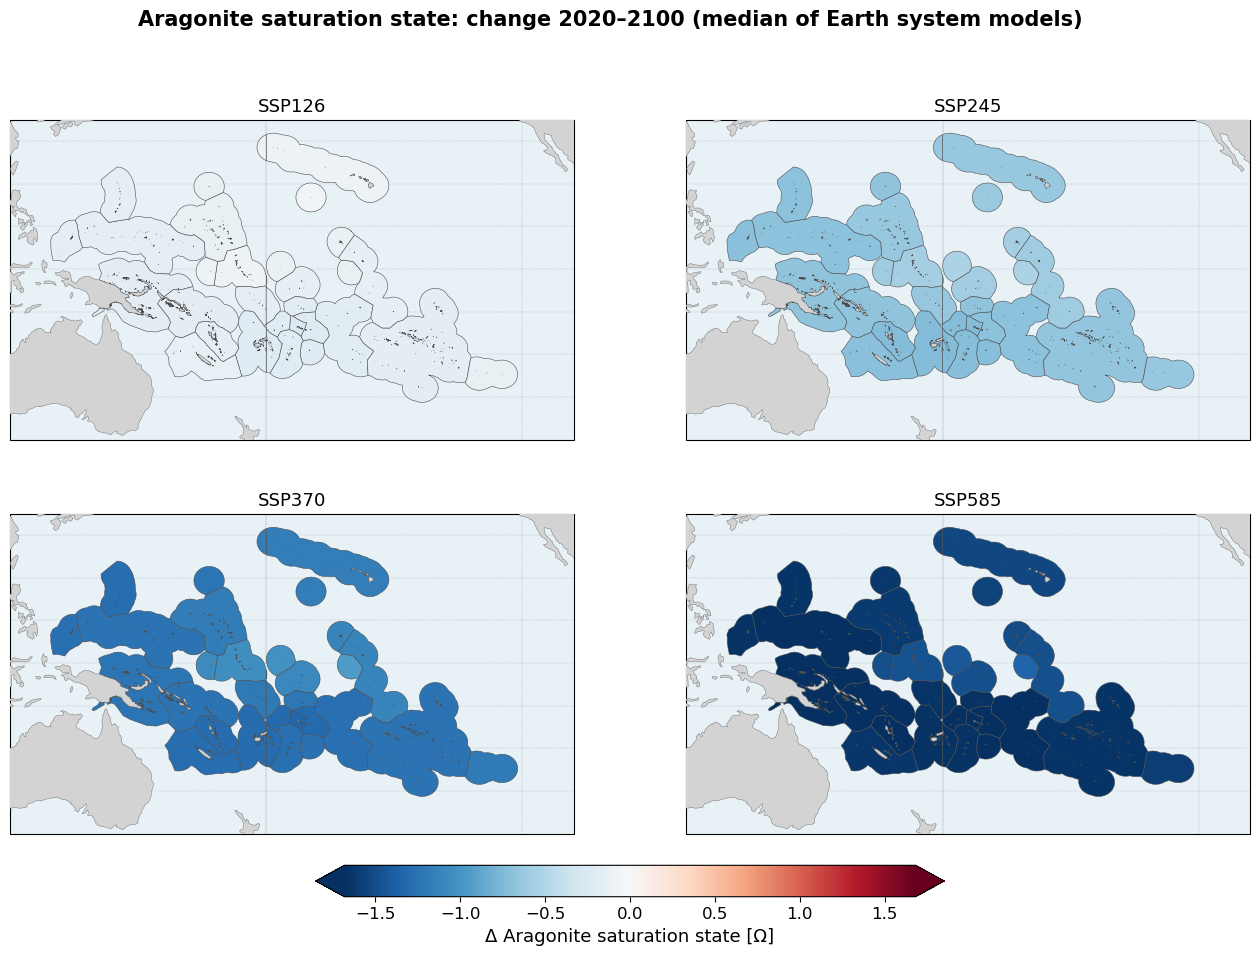

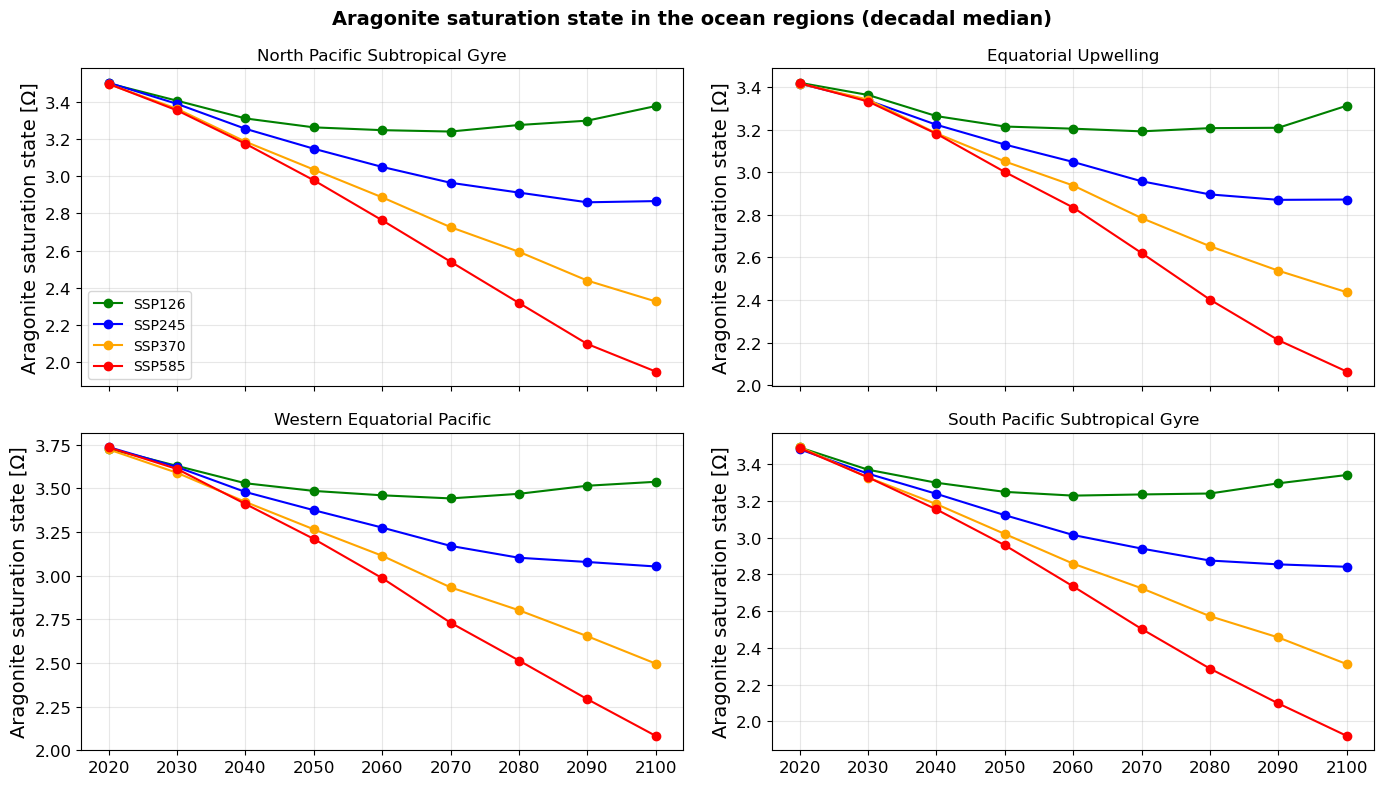

In [4]:
ds_ocads = reg.extract_ocads_regional("aragonite", eez, ssp_scenarios)
figs, tables = reg.ocads_report(ds_ocads, "aragonite", "Aragonite saturation state", "Ω", eez, ssp_scenarios, fig_dir, tables_dir, cmap="RdBu_r")
glue("aragonite_fig", figs["change"], display=False)
tables["regions"]